# 01 — Data sources, combinations, quality and exploratory visualization

Read this notebook **before modeling**. It creates a new, empty result directory; no prior model results are loaded. Then it inspects raw sources, reconstructs and audits the features, and profiles the frozen chronological splits.

**Reproducibility rerun after test inspection.** The historical test outcomes have already been seen. Descriptive inspection here does not make them an untouched holdout. Model settings and splits remain fixed; no hyperparameter choice is made from these plots.

The raw bundle remains frozen. Supplementary sources validate overlapping fixtures; they are **not concatenated as extra training samples**. Complete data tables behind the visualizations are exported alongside the figures.

In [1]:
from pathlib import Path
import sys, json
PROJECT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/study.py').exists())
sys.path.insert(0,str(PROJECT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from experiments import study, train
DATA=study.DATA; RUN=study.RUN
plt.rcParams.update({'font.size':11,'figure.figsize':(11,5),'axes.spines.top':False,'axes.spines.right':False})
BLUE='#236B8E'; GOLD='#B78126'; GREY='#737373'
def finish(name):
    plt.tight_layout()
    plt.savefig(RUN/'figures'/f'{name}.png',dpi=150,bbox_inches='tight')
    plt.show()

record=study.begin()
print('Fresh run:',record['run_id'],record['started_utc'])
print('Previous outputs loaded:',record['previous_outputs_loaded'])
sources=json.loads((DATA/'source_manifest.json').read_text())
raw=pd.read_csv(DATA/'raw/reza.csv',dtype={'Season':str})
print('Primary raw table:',raw.shape)
display(pd.DataFrame(sources)[['name','url','sha256']])

Fresh run: e3ceec90-4b79-4a9f-a6dc-b2dd43e67546 2026-10-26T05:55:08.441857+00:00
Previous outputs loaded: False
Primary raw table: (9880, 85)


,name,url,sha256
0,reza,https://raw.githubusercontent.com/RezaGooner/e...,f4145b15e6838ffe825d172130debb0be6f2f4e982df3b...
1,tara,https://raw.githubusercontent.com/tara-nguyen/...,eb35308565cc3d906b56bec76a009da53ea7dc6168f4df...
2,football_data_1516,https://www.football-data.co.uk/mmz4281/1516/E...,bd3502a18c38a1597fd9af62e2366b4015006d3528dd4d...
3,football_data_2425,https://www.football-data.co.uk/mmz4281/2425/E...,d0c8ce4a96d886cf60cf101f570f4a3893844226f91c7b...
4,football_data_2526,https://www.football-data.co.uk/mmz4281/2526/E...,3e3a8352f9ada6789c508d6ca184424421fed56a304009...


## 1. What is combined—and what is not?
Reza is the primary 26-season match archive. Tara covers ten overlapping seasons and checks common fields. Football-data 2015/16, 2024/25 and 2025/26 snapshots provide three season spot-checks. They do not increase the fixture count. Overlap cannot establish fully independent upstream provenance: providers may share underlying sources.

Below, fixture identity is season + normalized home team + away team. The plotted diagonal is each source's row count; off-diagonal cells count shared fixtures. The source URLs and hashes above identify the exact snapshots; this execution makes no freshness claim.

,source,rows,columns_after_normalization,first_date,last_date,unique_fixtures,overlap_with_primary,additional_fixtures
0,reza,9880,21,2000-08-19,2026-05-24,9880,9880,0
1,tara,3800,19,2010-08-14,2020-07-26,3800,3800,0
2,football_data_1516,380,19,2015-08-08,2016-05-17,380,380,0
3,football_data_2425,380,19,2024-08-16,2025-05-25,380,380,0
4,football_data_2526,380,19,2025-08-15,2026-05-24,380,380,0


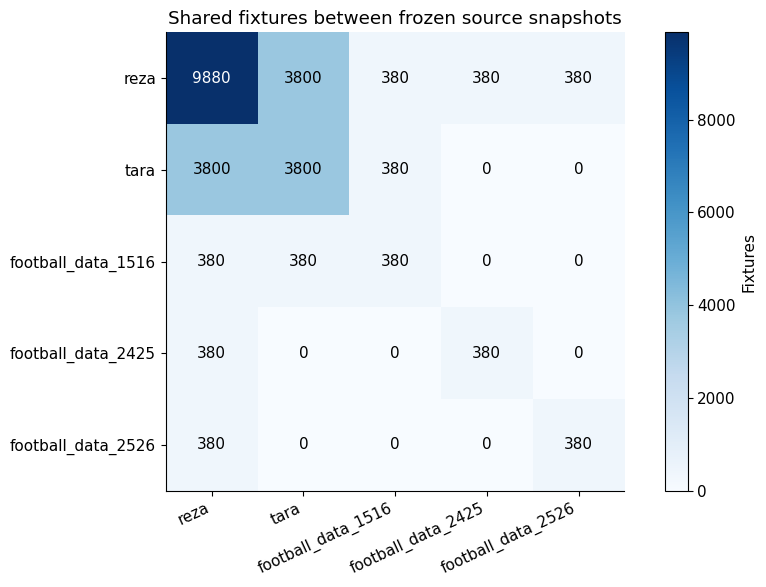

In [2]:
from experiments import audit
b=audit.b
canonical={'reza':b.canonical(raw,'reza'), 'tara':b.canonical(pd.read_csv(DATA/'raw/tara.csv'),'tara')}
for suffix in ['1516','2425','2526']:
    canonical['football_data_'+suffix]=b.canonical(pd.read_csv(DATA/f'raw/football_data_{suffix}.csv'),'fd',2000+int(suffix[:2]))
keys={name:set(map(tuple,frame[b.KEY].to_numpy())) for name,frame in canonical.items()}
primary=keys['reza']
source_summary=pd.DataFrame([{'source':name,'rows':len(frame),'columns_after_normalization':frame.shape[1], 'first_date':str(frame.date.min().date()),'last_date':str(frame.date.max().date()),'unique_fixtures':len(keys[name]),'overlap_with_primary':len(keys[name]&primary),'additional_fixtures':len(keys[name]-primary)} for name,frame in canonical.items()])
source_summary.to_csv(RUN/'data/source_summary.csv',index=False);display(source_summary)
overlap=pd.DataFrame({a:{b:len(keys[a]&keys[b]) for b in keys} for a in keys})
overlap.to_csv(RUN/'data/source_overlap.csv')
fig,ax=plt.subplots(figsize=(9,6));im=ax.imshow(overlap,cmap='Blues')
ax.set_xticks(range(len(keys)),list(keys),rotation=25,ha='right');ax.set_yticks(range(len(keys)),list(keys))
for i in range(len(keys)):
    for j in range(len(keys)):ax.text(j,i,str(overlap.iloc[i,j]),ha='center',va='center',color='white' if overlap.iloc[i,j]>5000 else 'black')
ax.set_title('Shared fixtures between frozen source snapshots');fig.colorbar(im,ax=ax,label='Fixtures')
finish('01_source_overlap')

### Source disagreements and resolution
The one overlapping measurement disagreement is inspected before cleaning. No extra copy of the fixture is added. Reza's 15 home shots for Aston Villa–West Ham on 2015-12-26 is retained; the bundled football-data season corroborates it. The independent audit below checks that exact comparison.

In [3]:
joined=canonical['reza'].merge(canonical['tara'],on=b.KEY,suffixes=('_reza','_tara'),validate='one_to_one')
conflicts=[]
for field in ['date','result',*b.MAP_T.values()]:
    for _,row in joined[joined[field+'_reza'].ne(joined[field+'_tara'])].iterrows():
        conflicts.append({**{key:row[key] for key in b.KEY},'field':field,'reza':row[field+'_reza'],'tara':row[field+'_tara']})
conflicts=pd.DataFrame(conflicts);conflicts.to_csv(RUN/'data/source_conflicts.csv',index=False);display(conflicts)
print('Primary fixtures retained:',len(primary),'Supplementary additions:',sum(len(v-primary) for k,v in keys.items() if k!='reza'))

,season_start,home_team,away_team,field,reza,tara
0,2015,Aston Villa,West Ham,home_shots,15.0,5


Primary fixtures retained: 9880 Supplementary additions: 0


## 2. Raw coverage over time
Coverage is checked before trusting the source README. Every season should contain 380 matches and 20 clubs. Arsenal should contribute 38 appearances per full season. The raw archive includes measurements and end-of-season metadata; those columns are not automatically valid predictors.

,matches,first_date,last_date,Arsenal_matches
season_start,,,,
2000,380,2000-08-19,2001-05-19,38
2001,380,2001-08-18,2002-05-11,38
2002,380,2002-08-17,2003-05-11,38
2003,380,2003-08-16,2004-05-15,38
2004,380,2004-08-14,2005-05-15,38
2005,380,2005-08-13,2006-05-07,38
2006,380,2006-08-19,2007-05-13,38
2007,380,2007-08-11,2008-05-11,38
2008,380,2008-08-16,2009-05-24,38


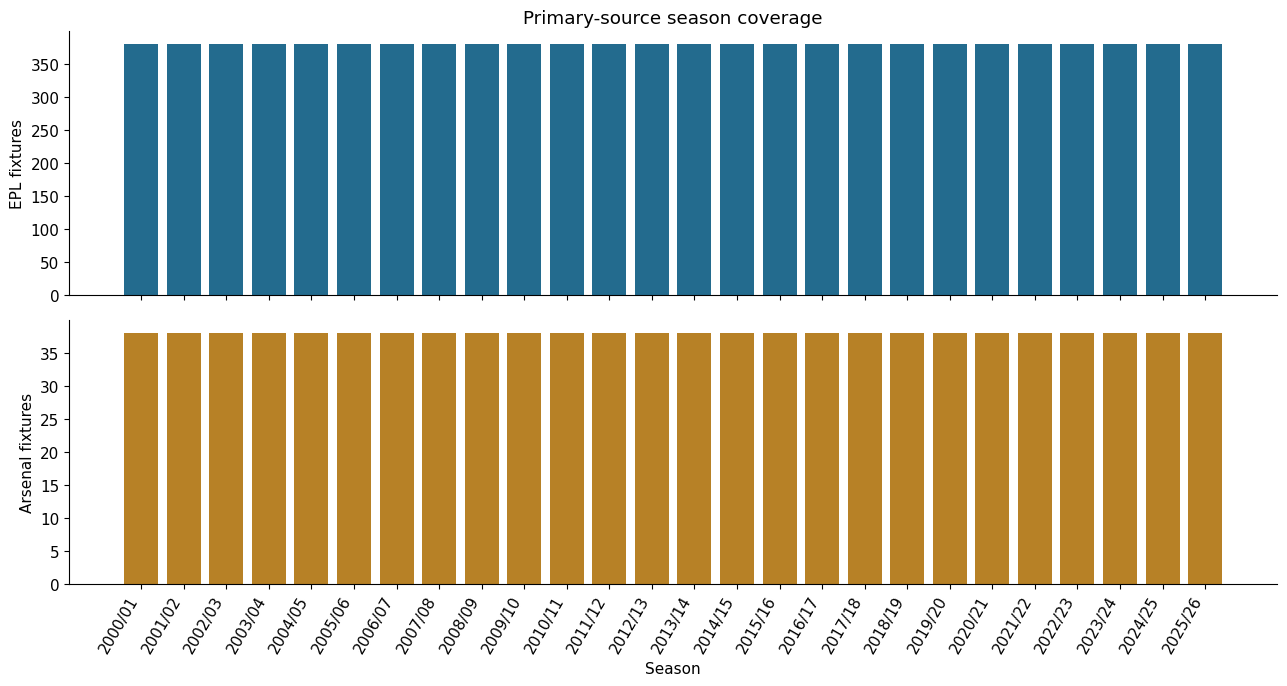

In [4]:
r=canonical['reza']
coverage=r.groupby('season_start').agg(matches=('result','size'),first_date=('date','min'),last_date=('date','max'))
coverage['Arsenal_matches']=r.assign(Arsenal=r.home_team.eq('Arsenal')|r.away_team.eq('Arsenal')).groupby('season_start').Arsenal.sum()
coverage.to_csv(RUN/'data/season_coverage.csv');display(coverage)
fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
x=np.arange(len(coverage));labels=[f'{y}/{str(y+1)[-2:]}' for y in coverage.index]
axes[0].bar(x,coverage.matches,color=BLUE);axes[0].set(ylabel='EPL fixtures',title='Primary-source season coverage')
axes[1].bar(x,coverage.Arsenal_matches,color=GOLD);axes[1].set(ylabel='Arsenal fixtures',xlabel='Season')
axes[1].set_xticks(x,labels,rotation=60,ha='right');finish('02_season_coverage')

## 3. Missingness and source-column inventory
Missing xG is not a zero measurement. xG availability changes by era and provider continuity is unverified, so xG is excluded from the fixed 39-feature model. Exported inventory lists every raw column, type, missing count and uniqueness. The chart highlights the largest missing fractions rather than hiding the rest.

,dtype,missing,missing_percent,unique_nonmissing
XGAway,float64,7023,71.082996,101
XGHome,float64,7022,71.072874,112
H2HForm,object,797,8.066802,361
AwayForm,object,26,0.263158,292
HomeForm,object,20,0.202429,286
Time,object,0,0.000000,46
Round,float64,0,0.000000,38
HomeTeam,object,0,0.000000,46
AwayTeam,object,0,0.000000,46
HomeGoal,int64,0,0.000000,10


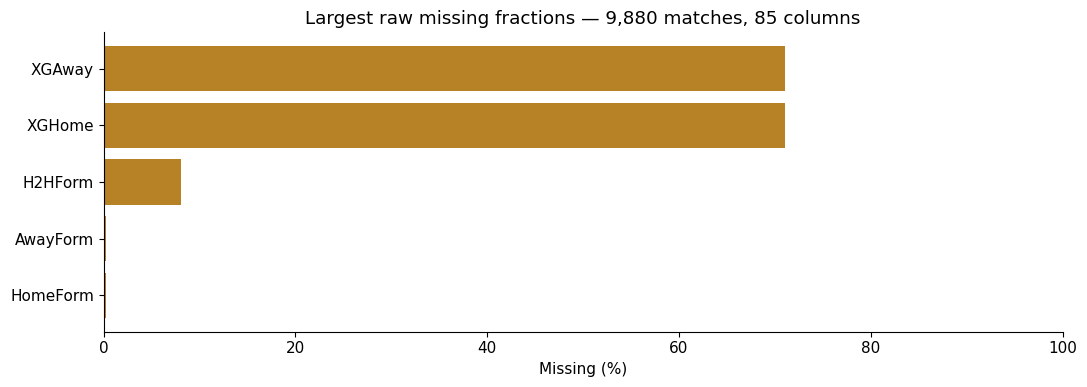

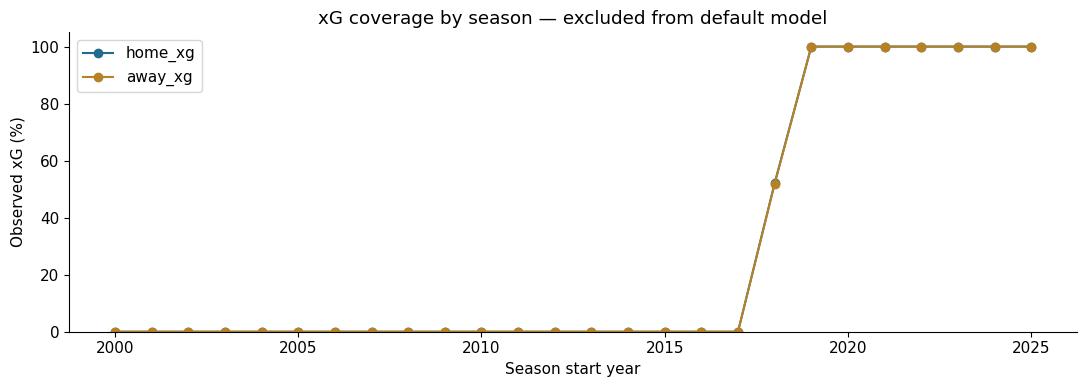

In [5]:
inventory=pd.DataFrame({'dtype':raw.dtypes.astype(str),'missing':raw.isna().sum(),'missing_percent':raw.isna().mean()*100,'unique_nonmissing':raw.nunique()})
inventory.to_csv(RUN/'data/raw_column_inventory.csv')
display(inventory.sort_values('missing_percent',ascending=False).head(20))
missing=inventory[inventory.missing>0].sort_values('missing_percent')
fig,ax=plt.subplots(figsize=(11,4));ax.barh(missing.index,missing.missing_percent,color=GOLD)
ax.set(xlim=(0,100),xlabel='Missing (%)',title=f'Largest raw missing fractions — {len(raw):,} matches, {raw.shape[1]} columns');finish('03_raw_missingness')
xg=r.groupby('season_start')[['home_xg','away_xg']].agg(lambda s:s.notna().mean()*100)
xg.to_csv(RUN/'data/xg_availability.csv')
xg.plot(marker='o',color=[BLUE,GOLD],figsize=(11,4));plt.ylim(0,105);plt.ylabel('Observed xG (%)');plt.xlabel('Season start year');plt.title('xG coverage by season — excluded from default model');finish('04_xg_coverage')

## 4. Team coverage and raw outcome distributions
The training population is broader than Arsenal: promoted/relegated teams have unequal historical coverage. Source rows count matches; summing appearances counts each match twice. Home/away outcome categories are H/D/A; they become Arsenal win/draw/loss only after reorientation.

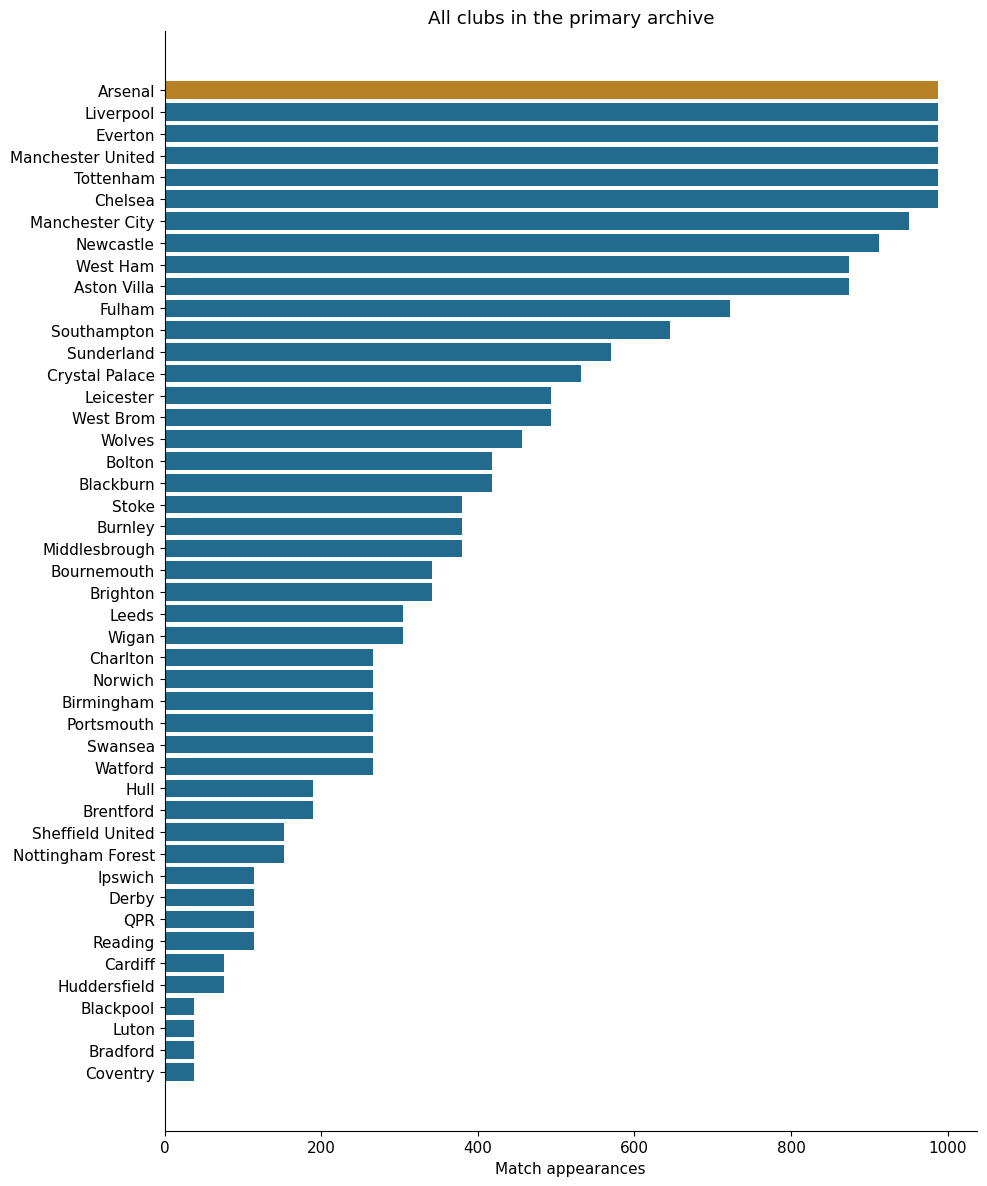

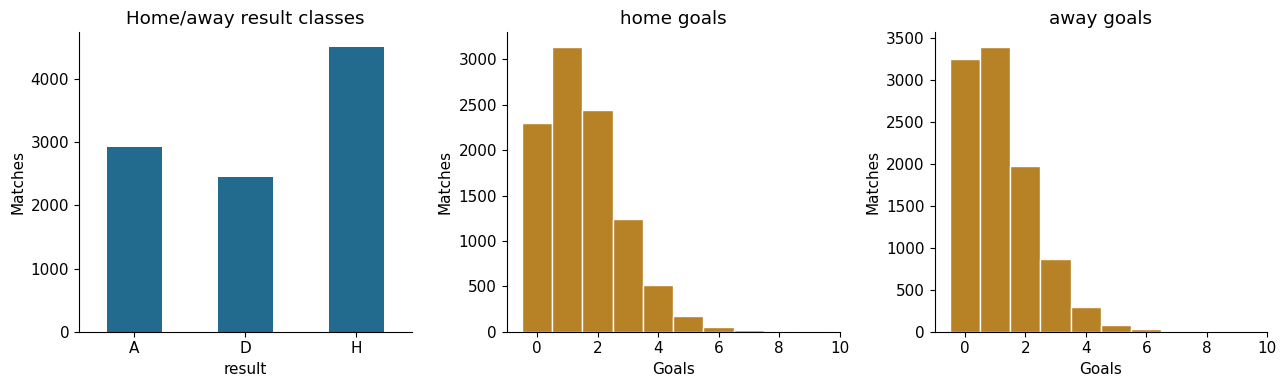

In [6]:
appearances=pd.concat([r.home_team,r.away_team]).value_counts().sort_values()
appearances.rename('appearances').to_csv(RUN/'data/team_coverage.csv')
fig,ax=plt.subplots(figsize=(10,12));ax.barh(appearances.index,appearances,color=[GOLD if name=='Arsenal' else BLUE for name in appearances.index]);ax.set(xlabel='Match appearances',title='All clubs in the primary archive');finish('05_team_coverage')
fig,axes=plt.subplots(1,3,figsize=(13,4))
r.result.value_counts().reindex(['A','D','H']).plot.bar(ax=axes[0],color=BLUE,rot=0);axes[0].set(title='Home/away result classes',ylabel='Matches')
for ax,field in zip(axes[1:],['home_goals','away_goals']):
    ax.hist(r[field],bins=np.arange(r[field].max()+2)-.5,color=GOLD,edgecolor='white');ax.set(title=field.replace('_',' '),xlabel='Goals',ylabel='Matches')
finish('06_raw_outcomes')

## 5. Reconstruct and audit before modeling
The audit checks raw hashes, source overlap, raw-to-clean equality, season counts, every reconstructed feature, all X/y/index cells, eligibility and chronological split membership. It also mutates later observations and verifies earlier features do not change.

Five inconsistent shot-stat team sides across three matches become missing; no result label is invented. End-of-season metadata repairs are logged separately and remain excluded from predictors. No source bytes are overwritten.

In [7]:
verification=audit.run(RUN/'audit')
display(pd.Series(verification))
clean=pd.read_csv(DATA/'data/matches_clean.csv')
full=pd.read_csv(DATA/'data/prematch_all.csv')
shot_flags=clean[clean.home_shots_quality_flag|clean.away_shots_quality_flag]
display(shot_flags[['date','home_team','away_team','home_shots','home_sot','away_shots','away_sot']])
corrections=pd.read_csv(RUN/'audit/metadata_corrections.csv');display(corrections.groupby(['column','basis']).size().rename('cells').reset_index())

passed                                                                              True
matches                                                                             9880
reproduced_features                                                                 9880
correction_cells                                                                      57
raw_preserved                                                                       True
remote_football_data_verified                                                      False
original_provider_per_cell_verified                                                False
checks                                 [raw SHA256, raw-to-clean equality, season cou...
dtype: object

,date,home_team,away_team,home_shots,home_sot,away_shots,away_sot
80,2000-10-14,Coventry,Tottenham,NaN,NaN,NaN,NaN
317,2001-04-13,Bradford,Charlton,NaN,NaN,NaN,NaN
7988,2021-08-15,Newcastle,West Ham,17.0,3.0,NaN,NaN


,column,basis,cells
0,SeasonGDAway,GF minus GA; algebraic repair only,19
1,SeasonGDHome,GF minus GA; algebraic repair only,19
2,SeasonWinAway,Recomputed from frozen season match results,19


## 8. Eligibility, fixed splits and class balance
Exclusion is an eligibility decision, not deletion from the archive. Missing lag histories can disproportionately exclude newly promoted teams and early-season fixtures. The chronological split is fixed before this rerun. Because historical tests were inspected earlier, these descriptive test distributions are disclosed as post-inspection EDA, not model-tuning evidence.

core_ready,Excluded,Eligible
split,,
train,383,7977
validation,30,730
test,28,732


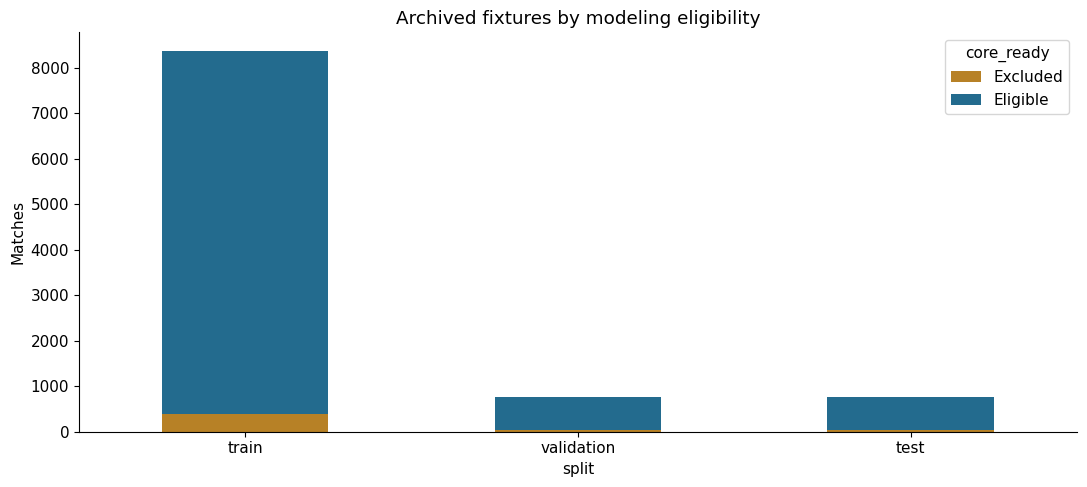

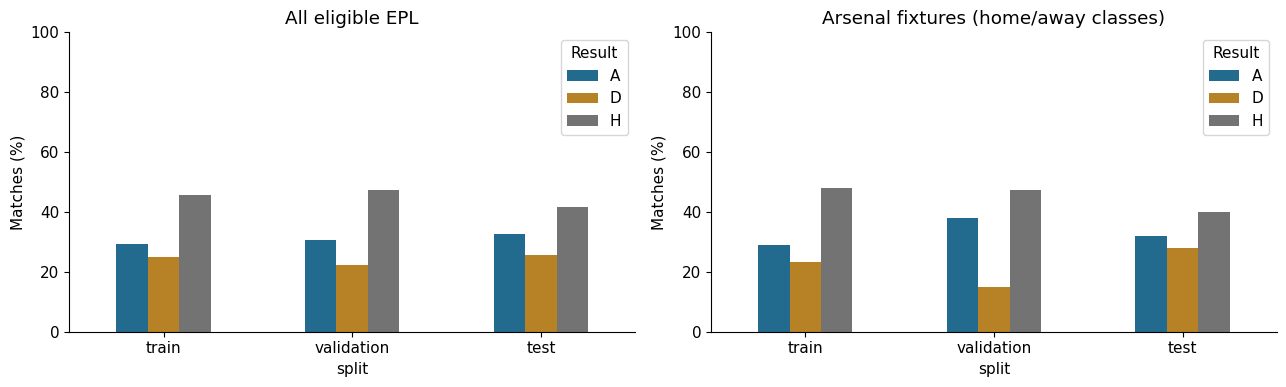

,rows,first_date,last_date,Arsenal_rows
split,,,,
train,7977,2000-09-16,2022-05-22,815
validation,730,2022-08-05,2024-05-19,74
test,732,2024-08-16,2026-05-24,75


In [8]:
split_order=['train','validation','test']
counts=pd.crosstab(full.split,full.core_ready).reindex(split_order).rename(columns={False:'Excluded',True:'Eligible'})
counts.to_csv(RUN/'data/eligibility.csv');display(counts)
counts.plot.bar(stacked=True,color=[GOLD,BLUE],rot=0);plt.ylabel('Matches');plt.title('Archived fixtures by modeling eligibility');finish('07_eligibility')
ready=full[full.core_ready];arsenal_mask=ready.home_team.eq('Arsenal')|ready.away_team.eq('Arsenal')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,subset,title in [(axes[0],ready,'All eligible EPL'),(axes[1],ready[arsenal_mask],'Arsenal fixtures (home/away classes)')]:
    balance=pd.crosstab(subset.split,subset.target_result,normalize='index').reindex(split_order).reindex(columns=['A','D','H'])*100
    balance.to_csv(RUN/'data'/('class_balance_'+('Arsenal' if ax is axes[1] else 'EPL')+'.csv'))
    balance.plot.bar(ax=ax,color=[BLUE,GOLD,GREY],rot=0);ax.set(title=title,ylabel='Matches (%)',ylim=(0,100));ax.legend(title='Result')
finish('08_class_balance')
split_table=ready.groupby('split').agg(rows=('match_id','size'),first_date=('date','min'),last_date=('date','max')).reindex(split_order)
split_table['Arsenal_rows']=ready[arsenal_mask].groupby('split').size()
split_table.to_csv(RUN/'data/split_summary.csv');display(split_table)

## 9. Feature construction and training-only distributions
The default inputs are 32 lagged performance means (home/away × 5/10-match windows × 8 statistics), four prior-appearance/rest variables, and three Elo variables. Histories use strictly earlier dates, with at least five valid observations; 10-match means may use fewer than ten when the minimum is met. Current-match goals, result, shots, and end-of-season standings are excluded as direct predictors.

Only **training rows** enter the following distribution/correlation plots. The full 39-column description and correlation matrix are exported. Small selected views keep the figures readable without dropping data from the exports.

,count,mean,std,min,25%,50%,75%,max,missing
home_goals_for_mean5,7977.0,1.323,0.633,0.000,0.800,1.200,1.600,5.800,0
home_goals_against_mean5,7977.0,1.346,0.602,0.000,1.000,1.400,1.800,4.000,0
home_shots_for_mean5,7977.0,11.967,2.957,4.000,10.000,11.600,13.600,24.600,0
home_shots_against_mean5,7977.0,12.165,2.977,3.600,10.200,12.200,14.000,25.800,0
home_sot_for_mean5,7977.0,5.384,1.930,0.800,4.000,5.200,6.600,14.600,0
home_sot_against_mean5,7977.0,5.471,1.880,0.800,4.000,5.200,6.600,14.000,0
home_corners_for_mean5,7977.0,5.389,1.491,0.800,4.400,5.200,6.200,12.000,0
home_points_mean5,7977.0,1.359,0.679,0.000,0.800,1.400,1.800,3.000,0
home_goals_for_mean10,7977.0,1.333,0.519,0.200,1.000,1.300,1.600,4.500,0
home_goals_against_mean10,7977.0,1.336,0.470,0.000,1.000,1.300,1.600,3.400,0


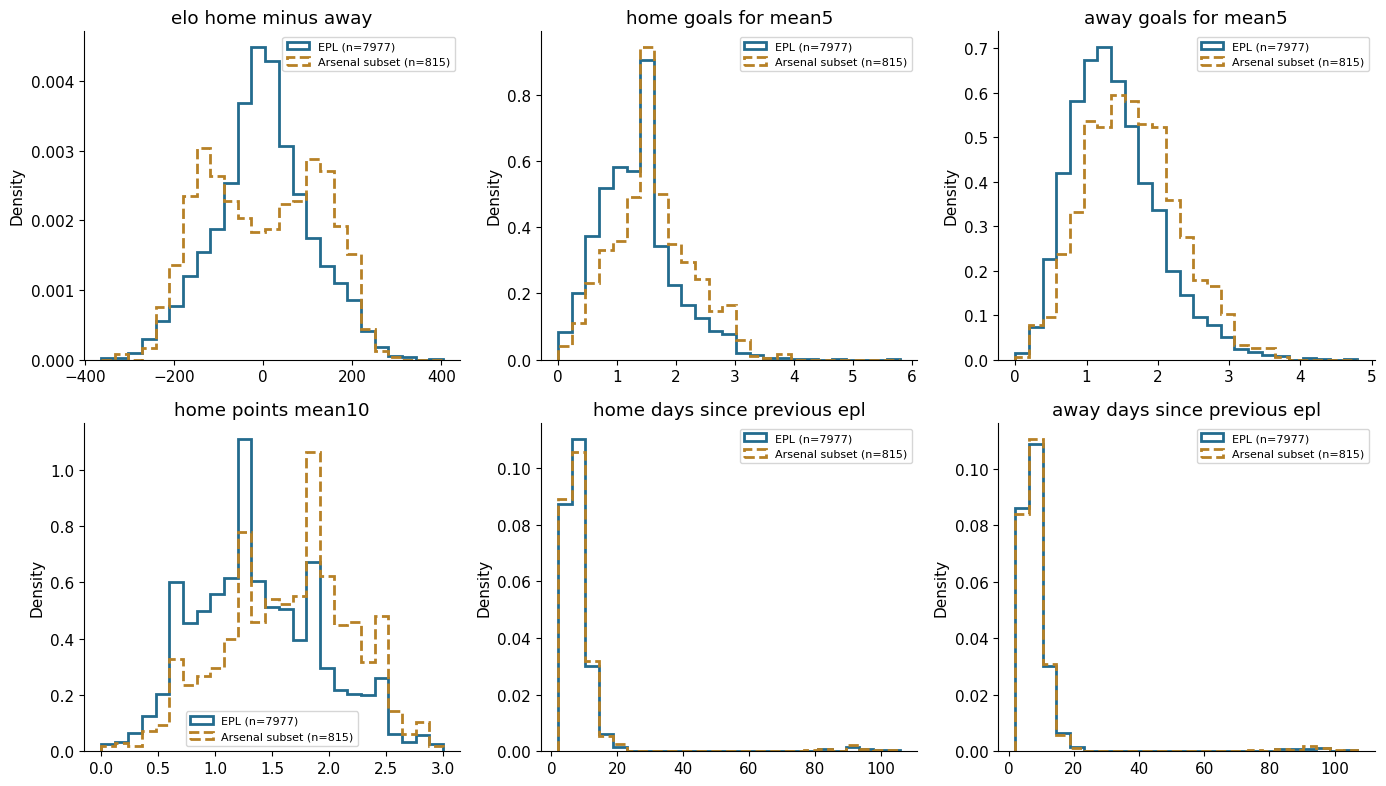

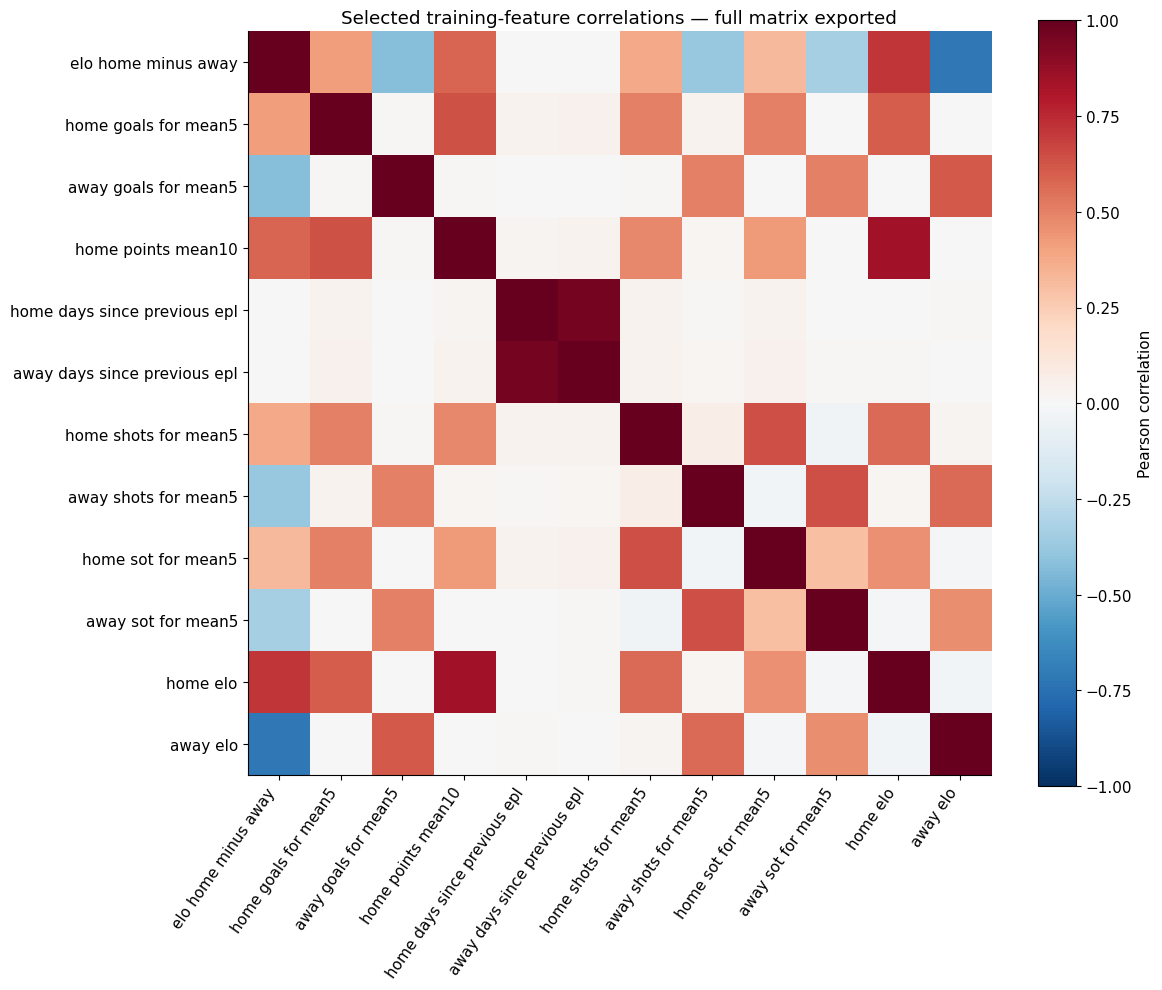

In [9]:
schema=json.loads((DATA/'feature_schema.json').read_text());features=schema['features']
xt=pd.read_csv(DATA/'data/train/X.csv');mt=pd.read_csv(DATA/'data/train/index.csv');am=mt.home_team.eq('Arsenal')|mt.away_team.eq('Arsenal')
feature_summary=xt.describe().T;feature_summary['missing']=xt.isna().sum();feature_summary.to_csv(RUN/'data/training_feature_summary.csv')
with pd.option_context('display.max_rows',None):display(feature_summary.round(3))
selected=['elo_home_minus_away','home_goals_for_mean5','away_goals_for_mean5','home_points_mean10','home_days_since_previous_epl','away_days_since_previous_epl']
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,field in zip(axes.flat,selected):
    bins=np.histogram_bin_edges(xt[field],bins=25)
    ax.hist(xt[field],bins=bins,density=True,histtype='step',linewidth=2,color=BLUE,label=f'EPL (n={len(xt)})')
    ax.hist(xt.loc[am,field],bins=bins,density=True,histtype='step',linestyle='--',linewidth=2,color=GOLD,label=f'Arsenal subset (n={am.sum()})')
    ax.set(title=field.replace('_',' '),ylabel='Density');ax.legend(fontsize=8)
finish('09_training_feature_distributions')
corr=xt.corr();corr.to_csv(RUN/'data/training_feature_correlations.csv')
chosen=selected+['home_shots_for_mean5','away_shots_for_mean5','home_sot_for_mean5','away_sot_for_mean5','home_elo','away_elo']
fig,ax=plt.subplots(figsize=(12,10));im=ax.imshow(corr.loc[chosen,chosen],cmap='RdBu_r',vmin=-1,vmax=1)
labels=[s.replace('_',' ') for s in chosen];ax.set_xticks(range(len(chosen)),labels,rotation=55,ha='right');ax.set_yticks(range(len(chosen)),labels);ax.set_title('Selected training-feature correlations — full matrix exported');fig.colorbar(im,ax=ax,label='Pearson correlation');finish('10_training_correlations')

## Data review conclusion and handoff
The supplementary sources check the primary archive without expanding its training population. All modeling features and split files are independently reconstructed before fitting. Missing xG and end-of-season metadata are excluded from the default inputs; eligibility and team-coverage biases remain limitations.

Continue to notebook 02 only after the audit passes. The next notebook records initialization and every epoch. The original raw bundle's audit files are historical metadata; this notebook's `results/current/audit/` is the fresh verification.

In [10]:
study.data_complete(verification)
print('Data stage complete:',study.manifest()['stage'])
print('Audit:',RUN/'audit/verification.json')
print('All data tables:',RUN/'data')

Data stage complete: data_verified
Audit: /workspace/Premier-League-Research/results/current/audit/verification.json
All data tables: /workspace/Premier-League-Research/results/current/data
